# Will this student get placed? — analysis

**Task.** Predict `placed` (1 = received an offer through the placement cell) for a new, separate list of registered students. Scoring metric: **F1 for `placed = 1`**.

## Summary of decisions

| Decision | Choice | Why (evidence below) |
|---|---|---|
| `status_code` | **Excluded** | Near-perfect proxy for the label (92% / 2% placed by code). Almost certainly written *after* the outcome — target leakage. |
| `student_id` | **Excluded** (used only to label output) | No relationship with `placed`; it carries no real information. |
| `city_tier` | **Excluded** | Placed rate flat across tiers; adding it does not help CV. |
| Features used | `department`, `cgpa`, `backlogs`, `coding_score`, `internship_months`, `projects`, `workshops` | Each shows a stable, plausible relationship with placement. |
| Model | **L2 logistic regression** (C = 0.3) in one sklearn `Pipeline` | Matches or beats gradient boosting, random forest and ensembles; simplest and most explainable. |
| Decision threshold | **0.28** (not 0.5) | Chosen on out-of-fold probabilities to maximise F1; default 0.5 loses ~0.13 F1. |
| Expected F1 | **≈ 0.56** (bootstrap 95% range ≈ 0.53–0.59) | Honest nested estimate. The ≈ 0.92 you get with `status_code` is not real. |

Files: `predict.py` loads `model.joblib` (created by this notebook) and only scores; it never fits.

In [1]:
import os, subprocess, sys, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import joblib, sklearn
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.model_selection import RepeatedStratifiedKFold, StratifiedKFold
from sklearn.metrics import roc_auc_score
from sklearn.base import clone

# the exact cleaning function used at prediction time lives in predict.py
from predict import prepare, NUMERIC, CATEGORICAL, VALID_RANGE

warnings.filterwarnings("ignore")
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})
SEED = 42
DATA = next(p for p in ["data/train.csv", "train.csv"] if os.path.exists(p))
raw = pd.read_csv(DATA, dtype={"student_id": str})
y = raw["placed"].to_numpy()
print("loaded", DATA, raw.shape, "| sklearn", sklearn.__version__, "| pandas", pd.__version__)
raw.head()

loaded data/train.csv (2500, 11) | sklearn 1.8.0 | pandas 3.0.2

,student_id,department,city_tier,cgpa,backlogs,internship_months,coding_score,projects,workshops,status_code,placed
0,S00802,CSE,2,7.00,1.0,5,56.6,5,4,NaN,1
1,S02107,CSE,3,8.06,1.0,4,29.9,1,3,1.0,1
2,S01945,CSE,3,7.92,0.0,0,52.4,2,2,0.0,0
3,S01956,MECH,2,7.49,1.0,1,37.3,1,1,0.0,0
4,S01828,CSE,2,8.80,NaN,0,82.2,2,3,1.0,1


## 1. Data audit / EDA

Everything in this section is about *what the data looks like and whether it can be trusted*, before any model is built.

In [2]:
print("shape:", raw.shape)
print("duplicate student_id:", raw.student_id.duplicated().sum(),
      "| duplicate rows ignoring id:", raw.drop(columns="student_id").duplicated().sum())
print("\nclass balance of placed:")
print(raw.placed.value_counts().rename("n").to_frame().assign(share=lambda d: (d.n / d.n.sum()).round(3)))
print("\ndtypes:"); print(raw.dtypes.to_string())

shape: (2500, 11)
duplicate student_id: 0 | duplicate rows ignoring id: 1

class balance of placed:
           n  share
placed             
0       1798  0.719
1        702  0.281

dtypes:
student_id               str
department               str
city_tier              int64
cgpa                 float64
backlogs             float64
internship_months      int64
coding_score         float64
projects               int64
workshops              int64
status_code          float64
placed                 int64

In [3]:
miss = pd.DataFrame({
    "n_missing": raw.isna().sum(),
    "pct_missing": (raw.isna().mean() * 100).round(1),
})
# is "being missing" itself related to the outcome?
rate_if_missing, rate_if_present = {}, {}
for c in raw.columns.drop(["student_id", "placed"]):
    m = raw[c].isna()
    rate_if_missing[c] = raw.loc[m, "placed"].mean() if m.any() else np.nan
    rate_if_present[c] = raw.loc[~m, "placed"].mean()
miss["placed_rate_if_missing"] = pd.Series(rate_if_missing).round(3)
miss["placed_rate_if_present"] = pd.Series(rate_if_present).round(3)
miss[miss.n_missing > 0]

,n_missing,pct_missing,placed_rate_if_missing,placed_rate_if_present
cgpa,118,4.7,0.347,0.277
backlogs,168,6.7,0.298,0.280
coding_score,525,21.0,0.274,0.283
status_code,113,4.5,0.212,0.284


In [4]:
print(raw[NUMERIC + ["city_tier", "status_code"]].describe().T.round(2))
print("\nvalues outside the valid range (these would be set to missing by prepare()):")
bad = {c: int(((raw[c] < lo) | (raw[c] > hi)).sum()) for c, (lo, hi) in VALID_RANGE.items()}
print(bad)
print("\nraw department values:", sorted(raw.department.unique()))
print("city_tier values:", sorted(raw.city_tier.unique().tolist()))

                    count   mean    std  min   25%    50%    75%    max
cgpa               2382.0   7.27   0.85  5.0   6.7   7.29   7.86   10.0
backlogs           2332.0   0.74   0.87  0.0   0.0   1.00   1.00    6.0
internship_months  2500.0   1.98   2.14  0.0   0.0   1.00   4.00    6.0
coding_score       1975.0  54.28  16.31  5.2  43.4  54.30  65.20  100.0
projects           2500.0   1.51   1.29  0.0   1.0   1.00   2.00   10.0
workshops          2500.0   2.09   1.42  0.0   1.0   2.00   3.00    4.0
city_tier          2500.0   1.93   0.77  1.0   1.0   2.00   3.00    3.0
status_code        2387.0   0.29   0.46  0.0   0.0   0.00   1.00    1.0

values outside the valid range (these would be set to missing by prepare()):
{'cgpa': 0, 'backlogs': 0, 'internship_months': 0, 'coding_score': 0, 'projects': 0, 'workshops': 0}

raw department values: ['CIVIL', 'CSE', 'ECE', 'EEE', 'IT', 'MECH']
city_tier values: [1, 2, 3]

,placed
backlogs,-0.167
city_tier,0.020
workshops,0.048
internship_months,0.115
projects,0.147
coding_score,0.292
cgpa,0.309


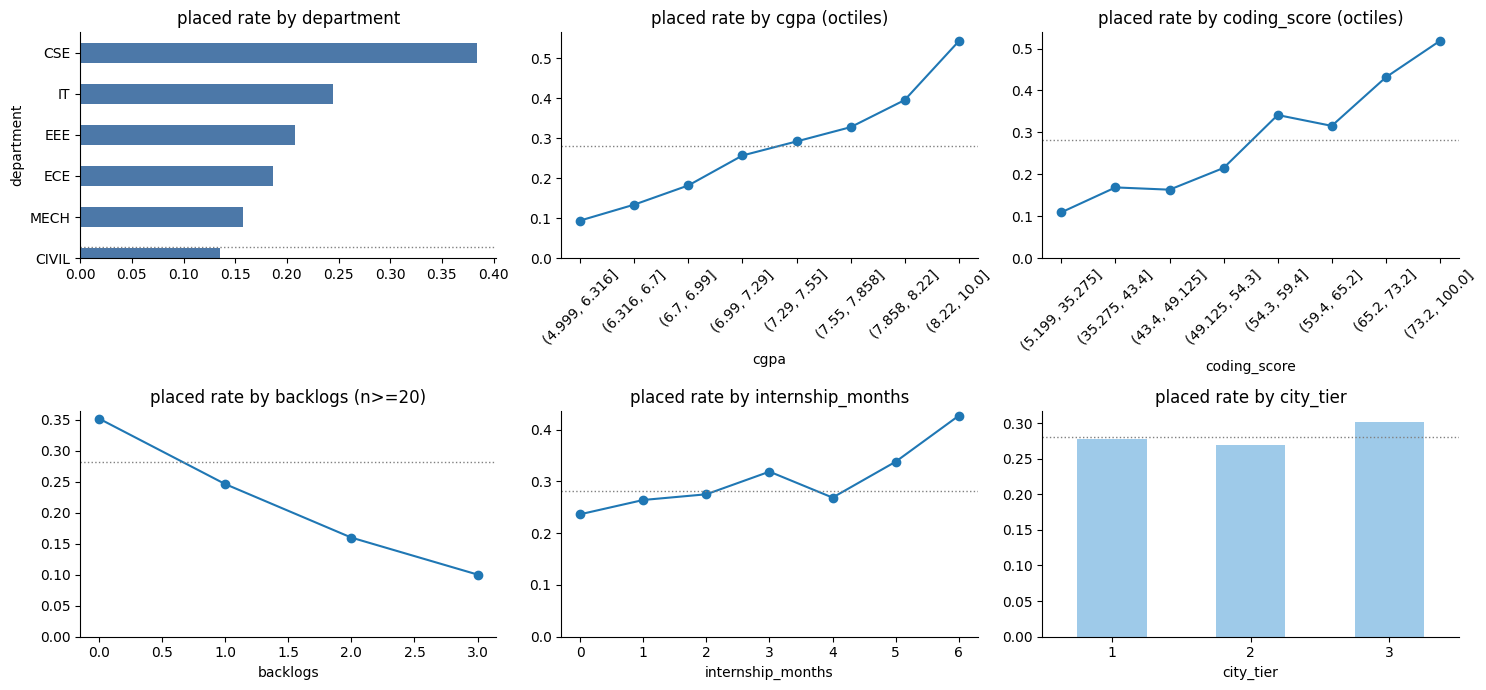

In [5]:
fig, ax = plt.subplots(2, 3, figsize=(15, 7))
d = raw.copy()
d.groupby("department").placed.mean().sort_values().plot.barh(ax=ax[0, 0], color="#4c78a8"); ax[0, 0].set_title("placed rate by department")
d.groupby(pd.qcut(d.cgpa, 8, duplicates="drop"), observed=True).placed.mean().plot(marker="o", ax=ax[0, 1]); ax[0, 1].set_title("placed rate by cgpa (octiles)"); ax[0, 1].tick_params(axis="x", rotation=45)
d.groupby(pd.qcut(d.coding_score, 8, duplicates="drop"), observed=True).placed.mean().plot(marker="o", ax=ax[0, 2]); ax[0, 2].set_title("placed rate by coding_score (octiles)"); ax[0, 2].tick_params(axis="x", rotation=45)
d.groupby("backlogs").placed.agg(["mean", "size"]).query("size >= 20")["mean"].plot(marker="o", ax=ax[1, 0]); ax[1, 0].set_title("placed rate by backlogs (n>=20)")
d.groupby("internship_months").placed.mean().plot(marker="o", ax=ax[1, 1]); ax[1, 1].set_title("placed rate by internship_months")
d.groupby("city_tier").placed.mean().plot.bar(ax=ax[1, 2], color="#9ecae9", rot=0); ax[1, 2].set_title("placed rate by city_tier")
for a in ax.ravel(): a.axhline(raw.placed.mean(), color="grey", ls=":", lw=1); a.set_ylim(0, None)
plt.tight_layout(); plt.show()
raw[NUMERIC + ["city_tier", "placed"]].corr(numeric_only=True)["placed"].drop("placed").round(3).sort_values()

In [6]:
# collinearity among the numeric predictors
raw[NUMERIC].corr().round(2)

,cgpa,backlogs,internship_months,coding_score,projects,workshops
cgpa,1.00,-0.21,-0.01,0.55,0.19,0.02
backlogs,-0.21,1.00,-0.03,-0.17,-0.07,0.01
internship_months,-0.01,-0.03,1.00,0.02,0.02,-0.02
coding_score,0.55,-0.17,0.02,1.00,0.11,0.05
projects,0.19,-0.07,0.02,0.11,1.00,-0.01
workshops,0.02,0.01,-0.02,0.05,-0.01,1.00


**What the audit shows**

- **2,500 rows, no duplicated ids.** One row is duplicated ignoring the id; that is negligible and left in.
- **Class balance: 28.1% placed.** Imbalanced enough that accuracy is misleading (always predicting 0 is 72% accurate with F1 = 0) and that the decision threshold will matter.
- **Missing values:** `coding_score` 21.0%, `backlogs` 6.7%, `cgpa` 4.7%, `status_code` 4.5%; the other columns are complete. For `coding_score` and `backlogs` the placed rate is the same whether the value is present or missing, so the missingness looks random. For `cgpa` the rate is higher when missing (34.7% vs 27.7%), but that rests on only 118 rows (about 1.6 standard errors) — suggestive at most. The test file may also have blanks, so imputation has to live inside the pipeline.
- **Values are valid.** No `cgpa` outside 0–10, no `coding_score` outside 0–100, no negative counts, `city_tier` ∈ {1, 2, 3}, and `department` has exactly six clean labels. `predict.py` still guards against all of this (it turns impossible values into missing, normalises case/whitespace in `department`, and winsorises extremes) because the unseen list may be messier than this file.
- **Relationships with the label** (plots above): `department` is the strongest single driver (CSE ≈ 38% placed vs CIVIL ≈ 14%); `cgpa` (r = +0.31) and `coding_score` (r = +0.29) are next; `backlogs` is negative (−0.17); `projects` (+0.15) and `internship_months` (+0.12) are weaker positives; `workshops` and `city_tier` are close to noise.
- **Collinearity is mild.** The only notable pair is `cgpa`/`coding_score` (r = 0.55). That is fine for a regularised linear model.

## 2. The suspicious column: `status_code` - POSSIBLE DATA LEAKAGE

The README describes it only as "a field stored on the placement portal". A portal status field is typically updated **when something happens to the student** (offer released, record closed). If so, it is a *consequence* of the outcome, not something known when the student registers — which would make it target leakage.

**Evidence (cell above):**
- `status_code = 0` → only **2.0%** placed (33 of 1,687). `status_code = 1` → **92.1%** placed (645 of 700). Missing → 21.2%.
- The one-line rule "`status_code == 1`" matches the label for **95.5%** of rows and alone reaches **F1 = 0.92**.
- No ordinary pre-placement attribute (cgpa, coding score, projects…) comes anywhere close to that: together they only reach AUC ≈ 0.77.

A field this predictive, with this vague a description, is the pattern of a post-outcome artifact. If the separate scoring list was built from a registration-time export (the README says it has "the same columns except `placed`", but nothing guarantees `status_code` means the same thing there), a model leaning on it would either fail or behave unpredictably. **Decision: exclude it** — and quantify the cost in section 4 so the decision is transparent.

`student_id` was checked the same way: its number has correlation −0.012 with `placed`, and the placed rate is flat across id quintiles (0.26–0.32). No leakage via ordering; it is simply not a feature. It is kept only to write the output file.

In [7]:
ct = pd.crosstab(raw.status_code.fillna(-1).map({0.0: "0", 1.0: "1", -1.0: "missing"}), raw.placed)
ct["placed_rate"] = (ct[1] / ct.sum(axis=1)).round(3)
print(ct)
# how well does a one-line rule "status_code == 1" reproduce the label?
rule = (raw.status_code == 1).astype(int)
print("\nagreement of rule 'status_code==1' with placed:", round((rule == raw.placed).mean(), 3))
print("F1 of that rule alone:", round(2 * ((rule & raw.placed).sum()) / (rule.sum() + raw.placed.sum()), 3))

# the id: is there an order / numeric artefact?
num_id = raw.student_id.str.extract(r"(\d+)")[0].astype(int)
print("\ncorr(student_id number, placed):", round(num_id.corr(raw.placed), 3))
print(raw.groupby(pd.qcut(num_id, 5), observed=True).placed.mean().round(3).rename("placed rate by id quintile").to_string())

placed          0    1  placed_rate
status_code                        
0            1654   33        0.020
1              55  645        0.921
missing        89   24        0.212

agreement of rule 'status_code==1' with placed: 0.955
F1 of that rule alone: 0.92

corr(student_id number, placed): -0.012
0
(0.999, 500.8]      0.276
(500.8, 1000.6]     0.324
(1000.6, 1500.4]    0.258
(1500.4, 2000.2]    0.270
(2000.2, 2500.0]    0.276

## 3. Modelling setup

- **One `Pipeline`**: `prepare()` (shared with `predict.py`) → `ColumnTransformer` → model. The `prepare()` step coerces to numeric, turns impossible values into missing, normalises `department`, and winsorises to the 0.5–99.5 percentile range seen in training. Inside the pipeline: median imputation + scaling for numeric columns; constant `"UNKNOWN"` imputation + one-hot (`handle_unknown="ignore"`) for `department`.
- Because imputation, scaling and encoding sit **inside** the pipeline, cross-validation refits them on each training fold only — no leakage from validation folds.
- **Validation:** stratified 5-fold CV repeated 5 times (25 fits per model), always scored on **F1 for `placed = 1`**, using **out-of-fold probabilities**, with the decision threshold treated as a tunable parameter (a smoothed argmax over 0.10–0.70), since F1 is threshold-dependent and the default 0.5 is rarely optimal for a 28% positive class.
- Winsorising bounds were computed on all training rows; with values this narrow the effect on CV is negligible.

In [8]:
def make_pipeline(model, num_cols, cat_cols=("department",), indicator=False):
    num = Pipeline([("imp", SimpleImputer(strategy="median", add_indicator=indicator)),
                    ("sc", StandardScaler())])
    cat = Pipeline([("imp", SimpleImputer(strategy="constant", fill_value="UNKNOWN")),
                    ("oh", OneHotEncoder(handle_unknown="ignore"))])
    pre = ColumnTransformer([("num", num, list(num_cols)), ("cat", cat, list(cat_cols))])
    return Pipeline([("pre", pre), ("model", model)])

# winsorising bounds learned from the training data (stored in the artifact)
valid = prepare(raw)
BOUNDS = {c: (float(valid[c].quantile(0.005)), float(valid[c].quantile(0.995))) for c in NUMERIC}
X_base = prepare(raw, BOUNDS)

THRESH = np.round(np.arange(0.10, 0.71, 0.01), 2)
def f1_at(y, p, thr):
    pred = p >= thr
    tp = (pred & (y == 1)).sum()
    return 2 * tp / max(pred.sum() + (y == 1).sum(), 1)

N_REP, N_FOLD = 5, 5
def oof_proba(make_model, X, y, n_rep=N_REP, seed=SEED):
    """Out-of-fold probabilities, one row per CV repeat. Preprocessing is inside the pipeline,
    so imputation / scaling are fit on the training folds only."""
    cv = RepeatedStratifiedKFold(n_splits=N_FOLD, n_repeats=n_rep, random_state=seed)
    P = np.zeros((n_rep, len(y)))
    for i, (tr, te) in enumerate(cv.split(X, y)):
        m = make_model().fit(X.iloc[tr], y[tr])
        P[i // N_FOLD, te] = m.predict_proba(X.iloc[te])[:, 1]
    return P

def curve(P, y):
    return np.array([[f1_at(y, p, t) for t in THRESH] for p in P])   # (repeats, thresholds)

def smooth(v, w=7):
    k = np.ones(w) / w
    return np.convolve(np.pad(v, w // 2, mode="edge"), k, mode="valid")

def summarize(name, P, y):
    c = curve(P, y); mean = c.mean(0); sm = smooth(mean); j = int(sm.argmax())
    return {"model": name,
            "AUC": np.mean([roc_auc_score(y, p) for p in P]),
            "F1@0.5": c[:, list(THRESH).index(0.5)].mean(),
            "best_thr": THRESH[j],
            "F1@best_thr": c[:, j].mean(),
            "F1_std_over_repeats": c[:, j].std(),
            "F1_peak_unsmoothed": mean.max()}

def table(rows):
    return pd.DataFrame(rows).set_index("model").round(3).sort_values("F1@best_thr", ascending=False)

LR = lambda C=1.0, **kw: LogisticRegression(C=C, max_iter=3000, **kw)
print("preprocessing + helpers ready; winsorising bounds:", {k: tuple(round(x, 2) for x in v) for k, v in BOUNDS.items()})

preprocessing + helpers ready; winsorising bounds: {'cgpa': (5.0, 9.47), 'backlogs': (0.0, 4.0), 'internship_months': (0.0, 6.0), 'coding_score': (12.36, 94.55), 'projects': (0.0, 6.0), 'workshops': (0.0, 4.0)}

## 4. Ablation: what is `status_code` worth?

Same model, same CV, with and without the column.

In [9]:
X_leak = X_base.assign(status_code=raw.status_code.values)
rows = []
for name, X, cols in [("LR  WITHOUT status_code", X_base, NUMERIC),
                      ("LR  WITH status_code (leaky)", X_leak, NUMERIC + ["status_code"])]:
    P = oof_proba(lambda: make_pipeline(LR(), cols), X, y, n_rep=3)
    rows.append(summarize(name, P, y))
table(rows)[["AUC", "F1@0.5", "best_thr", "F1@best_thr"]]

,AUC,F1@0.5,best_thr,F1@best_thr
model,,,,
LR WITH status_code (leaky),0.971,0.922,0.53,0.922
LR WITHOUT status_code,0.767,0.442,0.26,0.567


With `status_code` the model "reaches" F1 ≈ 0.92 / AUC ≈ 0.97; without it, F1 ≈ 0.57 / AUC ≈ 0.77. The 0.35 F1 gap is entirely the leaked signal. I chose the honest number: a model that scores 0.92 in CV because of a post-outcome field would be expected to disappoint on a genuinely new list, and — more importantly — it would not be a model of *who gets placed*.

## 5. Which features and engineering are worth it?

Each variant is logistic regression with the same CV (5 repeats × 5 folds), thresholds tuned per variant.

In [10]:
def with_extra(X, city=False, inter=False, dept_cgpa=False):
    X = X.copy(); cols = list(NUMERIC)
    if city:
        X["city_tier"] = raw.city_tier.values; cols.append("city_tier")
    if inter:
        X["cgpa_x_coding"] = X.cgpa * X.coding_score / 100; cols.append("cgpa_x_coding")
    if dept_cgpa:
        z = (X.cgpa - X.cgpa.mean())
        for d in sorted(X.department.dropna().unique()):
            X[f"cgpa_x_{d}"] = z * (X.department == d); cols.append(f"cgpa_x_{d}")
    return X, cols

rows = []
for name, kw, ind in [("base (6 numeric + department)", {}, False),
                      ("base + missing-value flags", {}, True),
                      ("base + city_tier", {"city": True}, False),
                      ("base + cgpa*coding_score", {"inter": True}, False),
                      ("base + department x cgpa", {"dept_cgpa": True}, False)]:
    X, cols = with_extra(X_base, **kw)
    P = oof_proba(lambda: make_pipeline(LR(), cols, indicator=ind), X, y)
    rows.append(summarize(name, P, y))
feat_table = table(rows)
feat_table[["AUC", "F1@best_thr", "F1_std_over_repeats", "best_thr"]]

,AUC,F1@best_thr,F1_std_over_repeats,best_thr
model,,,,
base + city_tier,0.767,0.566,0.005,0.26
base (6 numeric + department),0.767,0.565,0.003,0.26
base + cgpa*coding_score,0.769,0.565,0.004,0.26
base + department x cgpa,0.766,0.565,0.003,0.26
base + missing-value flags,0.767,0.560,0.004,0.26


Every variant lands within **0.006 F1 of the others, which is inside the noise** (std over repeats ≈ 0.003–0.005, and real sampling noise is larger). So I keep the simplest setup:

- **`city_tier`**: no gain, and its placed rate is flat → dropped.
- **Missing-value indicator flags**: slightly *worse* (0.560 vs 0.565) and the missingness showed no reliable relationship with the label (except a weak, small-sample hint for `cgpa`) → not used. Plain median imputation is enough.
- **`cgpa × coding_score` and `department × cgpa` interactions**: no gain → not used. The relationships are essentially additive, which is also why a linear model is competitive.

## 6. Model comparison

Candidates: logistic regression over a range of regularisation strengths (plus a class-weighted version), a shallow regularised gradient-boosting model, a random forest, and simple probability-averaging ensembles. All use the same features and CV.

In [11]:
rows, OOF = [], {}
def run(name, make_model, X=X_base):
    OOF[name] = oof_proba(make_model, X, y); rows.append(summarize(name, OOF[name], y))

for c in [0.03, 0.1, 0.3, 1.0, 3.0]:
    run(f"LogReg C={c}", lambda c=c: make_pipeline(LR(c), NUMERIC))
run("LogReg C=0.3 balanced", lambda: make_pipeline(LR(0.3, class_weight="balanced"), NUMERIC))
run("HistGradBoost (shallow)", lambda: make_pipeline(HistGradientBoostingClassifier(max_depth=3, learning_rate=0.03, max_iter=200, min_samples_leaf=40, l2_regularization=1.0, random_state=SEED), NUMERIC))
run("RandomForest", lambda: make_pipeline(RandomForestClassifier(500, min_samples_leaf=15, max_features=0.5, n_jobs=-1, random_state=SEED), NUMERIC))

# simple probability-average ensembles of the out-of-fold predictions
OOF["Ensemble LR+HGB"] = (OOF["LogReg C=0.3"] + OOF["HistGradBoost (shallow)"]) / 2
rows.append(summarize("Ensemble LR+HGB", OOF["Ensemble LR+HGB"], y))
OOF["Ensemble LR+HGB+RF"] = (OOF["LogReg C=0.3"] + OOF["HistGradBoost (shallow)"] + OOF["RandomForest"]) / 3
rows.append(summarize("Ensemble LR+HGB+RF", OOF["Ensemble LR+HGB+RF"], y))
model_table = table(rows); model_table

,AUC,F1@0.5,best_thr,F1@best_thr,F1_std_over_repeats,F1_peak_unsmoothed
model,,,,,,
LogReg C=0.3,0.767,0.436,0.28,0.566,0.002,0.566
LogReg C=0.1,0.767,0.425,0.27,0.565,0.004,0.567
LogReg C=3.0,0.767,0.442,0.26,0.565,0.004,0.566
LogReg C=1.0,0.767,0.440,0.26,0.565,0.003,0.566
LogReg C=0.3 balanced,0.767,0.566,0.49,0.565,0.004,0.566
LogReg C=0.03,0.765,0.400,0.28,0.563,0.002,0.564
Ensemble LR+HGB,0.762,0.427,0.27,0.563,0.003,0.563
Ensemble LR+HGB+RF,0.760,0.423,0.28,0.562,0.004,0.563
RandomForest,0.751,0.408,0.30,0.557,0.008,0.560


**Reading the table**

- **Logistic regression is at the top on both metrics** — best AUC (0.767) and best F1 (≈ 0.565) — and the result is insensitive to the regularisation strength (C from 0.1 to 3 are indistinguishable), so C = 0.3 is a safe middle choice.
- **Tree models are slightly worse** (HistGradientBoosting 0.551, random forest 0.557; AUC ≈ 0.75). With ~2,500 rows and a weak, mostly additive signal, extra flexibility mainly fits noise.
- **Ensembles do not help** (0.562–0.563): averaging in the weaker tree models pulls the blend slightly below logistic regression alone, so the added complexity is not justified.
- **Class weighting vs thresholding:** `class_weight="balanced"` gives the same F1 (0.565) with the best threshold moving to ≈ 0.49. It is the same trade-off expressed differently, so I use plain logistic regression plus an explicit tuned threshold — it is easier to inspect and store.
- **F1 at 0.5 is ≈ 0.44** for the unweighted models; threshold tuning is worth about **+0.13 F1**, far more than any model choice.

**Choice: logistic regression, C = 0.3.** Simplicity and interpretability win ties, and a low-variance model is the safer bet on an unseen list.

## 7. Choosing the decision threshold

F1 weights precision and recall equally, and with only 28% positives the F1-optimal cutoff sits well below 0.5 (a model that is unsure about many students gains more from catching true placements than it loses from extra false alarms). I take the threshold from the *smoothed* mean out-of-fold F1 curve, so it is not an artefact of one noisy peak.

chosen threshold (argmax of smoothed mean F1): 0.28
plateau within 0.005 F1 of the peak: 0.23 - 0.31
F1 at chosen threshold: 0.566 +/- 0.002 (std over 5 CV repeats);   F1 at default 0.5: 0.436

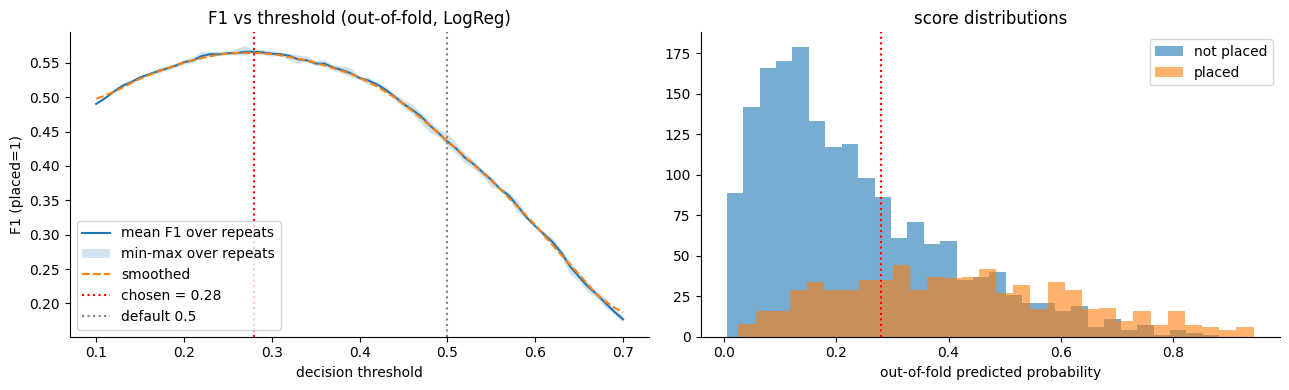

In [12]:
CHOSEN_C = 0.3
P = OOF[f"LogReg C={CHOSEN_C}"]
c = curve(P, y); mean = c.mean(0); sm = smooth(mean)
j = int(sm.argmax()); THRESHOLD = float(THRESH[j])
plateau = THRESH[sm >= sm.max() - 0.005]
print(f"chosen threshold (argmax of smoothed mean F1): {THRESHOLD:.2f}")
print(f"plateau within 0.005 F1 of the peak: {plateau.min():.2f} - {plateau.max():.2f}")
print(f"F1 at chosen threshold: {c[:, j].mean():.3f} +/- {c[:, j].std():.3f} (std over {N_REP} CV repeats);   F1 at default 0.5: {c[:, list(THRESH).index(0.5)].mean():.3f}")

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(THRESH, mean, label="mean F1 over repeats"); ax[0].fill_between(THRESH, c.min(0), c.max(0), alpha=0.2, label="min-max over repeats")
ax[0].plot(THRESH, sm, "--", label="smoothed")
ax[0].axvline(THRESHOLD, color="red", ls=":", label=f"chosen = {THRESHOLD:.2f}"); ax[0].axvline(0.5, color="grey", ls=":", label="default 0.5")
ax[0].set_xlabel("decision threshold"); ax[0].set_ylabel("F1 (placed=1)"); ax[0].legend(); ax[0].set_title("F1 vs threshold (out-of-fold, LogReg)")
ax[1].hist(P[0][y == 0], bins=30, alpha=0.6, label="not placed"); ax[1].hist(P[0][y == 1], bins=30, alpha=0.6, label="placed")
ax[1].axvline(THRESHOLD, color="red", ls=":"); ax[1].set_xlabel("out-of-fold predicted probability"); ax[1].legend(); ax[1].set_title("score distributions")
plt.tight_layout(); plt.show()

The curve is flat across roughly **0.23–0.31** (within 0.005 F1 of the peak), so the exact value is not critical. I use **0.28**, near the centre of that plateau. It is stored in `model.joblib` and applied by `predict.py`.

## 8. Honest performance estimate

Picking the threshold and judging performance on the same predictions is optimistic. Here the threshold is chosen **only from each outer-training fold** (inner CV) and then applied to the untouched outer test fold.

In [13]:
# Honest estimate: the threshold is chosen using ONLY the outer-training part (inner CV),
# then applied to the outer test fold that played no role in the choice.
def pick_threshold(Xtr, ytr, make_model):
    Pin = oof_proba(make_model, Xtr.reset_index(drop=True), ytr, n_rep=2, seed=1)
    m = np.mean([[f1_at(ytr, p, t) for t in THRESH] for p in Pin], axis=0)
    return THRESH[int(smooth(m).argmax())]

mk = lambda: make_pipeline(LR(CHOSEN_C), NUMERIC)
rep_f1, rep_auc, picked = [], [], []
for r in range(3):
    pred_all = np.zeros(len(y), int); prob_all = np.zeros(len(y))
    for tr, te in StratifiedKFold(5, shuffle=True, random_state=100 + r).split(X_base, y):
        t = pick_threshold(X_base.iloc[tr], y[tr], mk); picked.append(t)
        m = mk().fit(X_base.iloc[tr], y[tr]); p = m.predict_proba(X_base.iloc[te])[:, 1]
        prob_all[te] = p; pred_all[te] = (p >= t).astype(int)
    tp = ((pred_all == 1) & (y == 1)).sum()
    rep_f1.append(2 * tp / (pred_all.sum() + y.sum())); rep_auc.append(roc_auc_score(y, prob_all))
print("thresholds picked inside the outer folds:", sorted({round(float(t), 2) for t in picked}))
print(f"nested F1 (placed=1): {np.mean(rep_f1):.3f} +/- {np.std(rep_f1):.3f}   AUC: {np.mean(rep_auc):.3f}")

# The spread over CV repeats understates real uncertainty (same 2,500 rows every time).
# Bootstrap the rows of the last outer-test predictions to see how much F1 moves with the sample.
rng = np.random.default_rng(SEED); bs = []
for _ in range(1000):
    idx = rng.integers(0, len(y), len(y)); yy, pp = y[idx], pred_all[idx]
    bs.append(2 * ((pp == 1) & (yy == 1)).sum() / (pp.sum() + yy.sum()))
lo, hi = np.percentile(bs, [2.5, 97.5])
prec = ((pred_all == 1) & (y == 1)).sum() / pred_all.sum(); rec = ((pred_all == 1) & (y == 1)).sum() / y.sum()
print(f"bootstrap 95% interval for F1 on a list of this size (n={len(y)}): {lo:.3f} - {hi:.3f}")
print(f"precision {prec:.3f} | recall {rec:.3f} | share predicted placed {pred_all.mean():.3f}")

thresholds picked inside the outer folds: [0.25, 0.26, 0.27, 0.28, 0.29, 0.3]
nested F1 (placed=1): 0.560 +/- 0.001   AUC: 0.768
bootstrap 95% interval for F1 on a list of this size (n=2500): 0.530 - 0.588
precision 0.464 | recall 0.709 | share predicted placed 0.430

**Expected F1 ≈ 0.56.** The thresholds picked in different folds all fall in 0.25–0.30, i.e. the choice is stable. The spread across CV repeats is tiny only because they reuse the same 2,500 rows; the bootstrap interval (≈ 0.53–0.59) is the more realistic uncertainty, and a smaller scoring list will be noisier still.

At the chosen threshold the model favours **recall (≈ 0.71) over precision (≈ 0.46)** and flags about 43% of students as placed, versus 28% actually placed. That is the expected shape when F1 is optimised on a weak-signal, 28%-positive problem — it is the best available trade-off, not a bug.

## 9. Final model

Refit on **all** training rows with the settings above. The coefficients are on standardised features, so they are directly comparable.

in-sample F1 at threshold 0.28: 0.571 (optimistic - for reference only)
predicted-positive rate on train: 0.421  vs actual placed rate 0.281

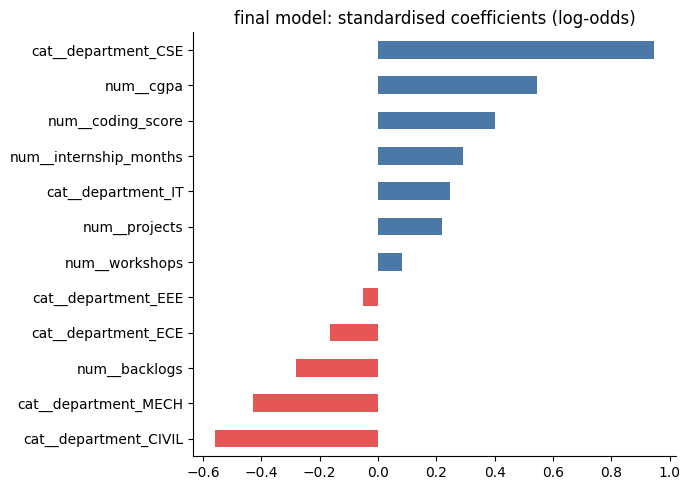

In [14]:
final = make_pipeline(LR(CHOSEN_C), NUMERIC).fit(X_base, y)

names = final.named_steps["pre"].get_feature_names_out()
coef = pd.Series(final.named_steps["model"].coef_[0], index=names).sort_values()
fig, ax = plt.subplots(figsize=(7, 5)); coef.plot.barh(ax=ax, color=np.where(coef > 0, "#4c78a8", "#e45756"))
ax.set_title("final model: standardised coefficients (log-odds)"); plt.tight_layout(); plt.show()

proba_train = final.predict_proba(X_base)[:, 1]
print(f"in-sample F1 at threshold {THRESHOLD:.2f}: {f1_at(y, proba_train, THRESHOLD):.3f} (optimistic - for reference only)")
print(f"predicted-positive rate on train: {(proba_train >= THRESHOLD).mean():.3f}  vs actual placed rate {y.mean():.3f}")

The coefficients agree with the exploratory analysis and with common sense, which is a useful check that nothing odd is being learned: **CSE** (and, less so, IT) raise placement odds while **CIVIL** and **MECH** lower them; higher **cgpa**, **coding_score**, **internship_months** and **projects** help; more **backlogs** hurts; **workshops** has a small effect. The in-sample F1 (0.57) is almost identical to the cross-validated value (0.56–0.57), so the model is not overfitting.

## 10. Saving the model and testing `predict.py`

The artifact `model.joblib` contains the fitted pipeline, the threshold, the winsorising bounds, and the feature list. `predict.py` loads it, runs the same `prepare()` cleaning, applies the saved threshold, and writes `student_id,placed`. It never calls `fit`.

In [15]:
artifact = {
    "pipeline": final,
    "threshold": THRESHOLD,
    "bounds": BOUNDS,
    "features": NUMERIC + CATEGORICAL,
    "excluded": ["status_code", "student_id", "city_tier"],
    "cv_f1": float(np.mean(rep_f1)),
    "sklearn_version": sklearn.__version__,
}
joblib.dump(artifact, "model.joblib")
print("saved model.joblib", round(os.path.getsize("model.joblib") / 1024, 1), "KB")

saved model.joblib 4.6 KB

**Tests run by the next cell**
1. `predict.py` on the full training file reproduces the in-notebook predictions exactly (so there is no train/serve skew).
2. A deliberately messy file — no `status_code` column, padded/lower-case department, an unseen department, a blank department, impossible `cgpa` and `coding_score`, blanks in several columns, an absurd `projects` value — still yields exactly one 0/1 row per input row.
3. A file with almost no columns, and an empty file, both run without error.
4. The output columns match `data/sample_submission.csv`.

In [16]:
from predict import predict_frame
# 1) the script on the full training file must reproduce the in-notebook predictions
subprocess.run([sys.executable, "predict.py", "--input", DATA, "--output", "/tmp/pred_train.csv"], check=True)
out = pd.read_csv("/tmp/pred_train.csv")
assert list(out.columns) == ["student_id", "placed"] and len(out) == len(raw) and (out.student_id == raw.student_id).all()
assert (out.placed.to_numpy() == (proba_train >= THRESHOLD).astype(int)).all()
print("OK: predict.py reproduces the notebook predictions;", out.placed.value_counts().to_dict())

# 2) stress test: a messy file like the hidden list might be (no status_code, no label)
messy = raw.drop(columns=["placed", "status_code"]).head(12).copy()
messy.loc[0, "department"] = " cse "         # case / whitespace
messy.loc[1, "department"] = "ARCHITECTURE"  # unseen category
messy.loc[2, "department"] = np.nan          # blank
messy.loc[3, "cgpa"] = 14.2                  # impossible value
messy.loc[4, "coding_score"] = -5            # impossible value
messy.loc[5, ["cgpa", "backlogs", "coding_score"]] = np.nan
messy.loc[6, "projects"] = 900               # wild outlier
messy.to_csv("/tmp/messy.csv", index=False)
subprocess.run([sys.executable, "predict.py", "--input", "/tmp/messy.csv", "--output", "/tmp/pred_messy.csv"], check=True)
pm = pd.read_csv("/tmp/pred_messy.csv"); assert len(pm) == len(messy) and set(pm.placed) <= {0, 1}

# 3) missing whole columns, and an empty file
raw[["student_id", "cgpa"]].head(5).to_csv("/tmp/few_cols.csv", index=False)
subprocess.run([sys.executable, "predict.py", "--input", "/tmp/few_cols.csv", "--output", "/tmp/pred_few.csv"], check=True)
raw.drop(columns="placed").head(0).to_csv("/tmp/empty.csv", index=False)
subprocess.run([sys.executable, "predict.py", "--input", "/tmp/empty.csv", "--output", "/tmp/pred_empty.csv"], check=True)

# 4) layout identical to data/sample_submission.csv
sample = pd.read_csv("data/sample_submission.csv") if os.path.exists("data/sample_submission.csv") else None
if sample is not None: assert list(sample.columns) == list(out.columns)
pm

OK: predict.py reproduces the notebook predictions; {0: 1448, 1: 1052}

,student_id,placed
0,S00802,1
1,S02107,0
2,S01945,0
3,S01956,0
4,S01828,1
5,S01794,0
6,S01864,1
7,S00144,0
8,S02319,0
9,S00775,1


## 11. Limitations and what I would monitor

- **Modest ceiling.** Without the leaked field, the usable signal is limited (AUC ≈ 0.77, F1 ≈ 0.56). More careful tuning will not change that much; better *information* (e.g. interview results, company-side data) would.
- **Distribution shift.** The scoring list is separate. If its department mix, cgpa range or missingness differs from training, performance and the optimal threshold may shift. The pipeline tolerates blanks, unseen departments and impossible values, but cannot fix a genuine change in the population. If the list is much more (or less) placed than 28%, the threshold should be revisited.
- **`status_code` assumption.** I judged it to be post-outcome from its behaviour and description, not from documentation. If the placement cell can confirm it is recorded at registration time *and* is populated the same way in the scoring list, the decision should be revisited — but I would want that confirmation in writing before relying on it.
- **Sampling noise.** F1 on a small list can move by several hundredths purely by chance (bootstrap interval ≈ ±0.03 at n = 2,500, wider for smaller lists).
- **Fairness note.** `department` is a strong predictor, reflecting real historical placement patterns. Using it is appropriate for forecasting who the cell will place, but it should not be read as a statement about individual students' merit, and the scores should not be the sole basis for deciding who receives support.
- **Possible next steps:** recalibrate the threshold on a labelled slice of the new list when available; track precision/recall by department over time.